# Predictive Box Office Revenue and Movie Success Analytics

Reproducible study using the supplied TMDB data. This executed notebook reconstructs cleaning,
checks chronological partitions, and presents the saved experiment. The full training implementation
is in `src/train.py`; rerun its module to regenerate every model and chart.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.data import load_data, make_features, split_data
raw, clean, audit = load_data()
display(pd.DataFrame([audit]))
display(clean[["title","budget","revenue","genres_list","success"]].head())

,raw_movies,raw_credits,matched_credits,zero_budget,zero_revenue,positive_financial_records,excluded_budget_below_1000,modeling_records,success_cases,below_threshold_cases,first_release,last_release
0,4803,4803,4803,1037,1427,3229,13,3216,1803,1413,1916-09-04,2016-09-09


,title,budget,revenue,genres_list,success
0,Intolerance,385907,8394751,[Drama],1
1,The Big Parade,245000,22000000,"[Drama, Romance, War]",1
2,Metropolis,92620000,650422,"[Drama, Science Fiction]",0
3,The Broadway Melody,379000,4358000,"[Drama, Music, Romance]",1
4,Hell's Angels,3950000,8000000,"[Action, Drama, History]",1


## Cleaning and experimental design
Zero financial values are excluded from supervised learning; budgets below $1,000 are excluded as suspicious. All preprocessing is train-fitted. Success means revenue ≥ 2 × budget.

In [2]:
train, validation, test = split_data(clean)
display(pd.DataFrame({"partition":["train","validation","test"],
                      "rows":[len(train),len(validation),len(test)],
                      "start":[x.release_date.min() for x in [train,validation,test]],
                      "end":[x.release_date.max() for x in [train,validation,test]]}))
X_train = make_features(train)
display(X_train.head())
assert train.release_date.max() < validation.release_date.min() < test.release_date.min()

,partition,rows,start,end
0,train,2433,1916-09-04,2010-12-29
1,validation,455,2011-01-01,2013-12-27
2,test,328,2014-01-01,2016-09-09


,log_budget,runtime,release_year,month_sin,month_cos,original_language,primary_company,director,genre_Action,genre_Adventure,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_TV Movie,genre_Thriller,genre_War,genre_Western
0,12.863354,197.0,1916,-1.000000,-1.836970e-16,en,Triangle Film Corporation,D.W. Griffith,0,0,...,0,0,0,0,0,0,0,0,0,0
1,12.409018,151.0,1925,-0.500000,8.660254e-01,en,Metro-Goldwyn-Mayer (MGM),King Vidor,0,0,...,0,0,0,0,1,0,0,0,1,0
2,18.344016,153.0,1927,0.500000,8.660254e-01,de,Paramount Pictures,Fritz Lang,0,0,...,0,0,0,0,0,1,0,0,0,0
3,12.845294,100.0,1929,0.866025,5.000000e-01,en,Metro-Goldwyn-Mayer (MGM),Harry Beaumont,0,0,...,0,0,1,0,1,0,0,0,0,0
4,15.189226,127.0,1930,-0.500000,8.660254e-01,en,The Caddo Company,James Whale,1,0,...,1,0,0,0,0,0,0,0,0,0


## Exploratory analysis
These charts describe the entire eligible sample. They do not supply fitted preprocessing statistics to models.

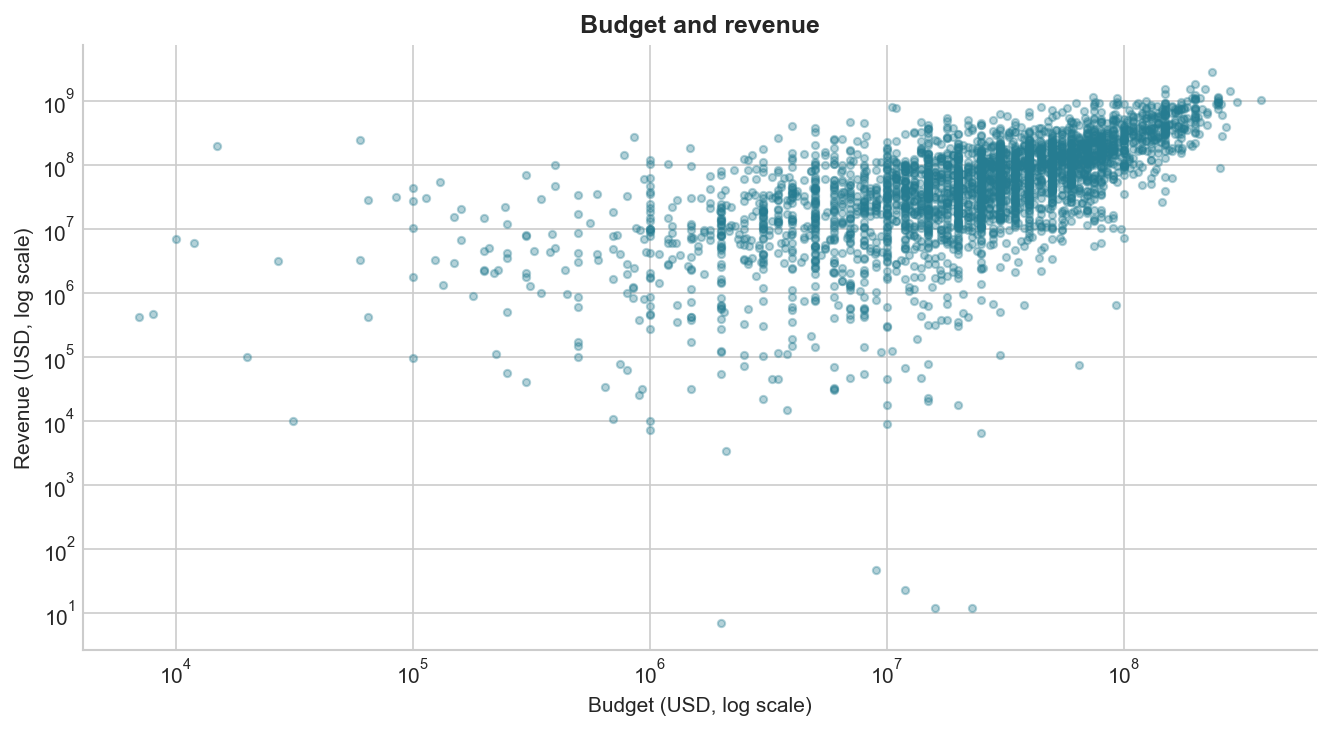

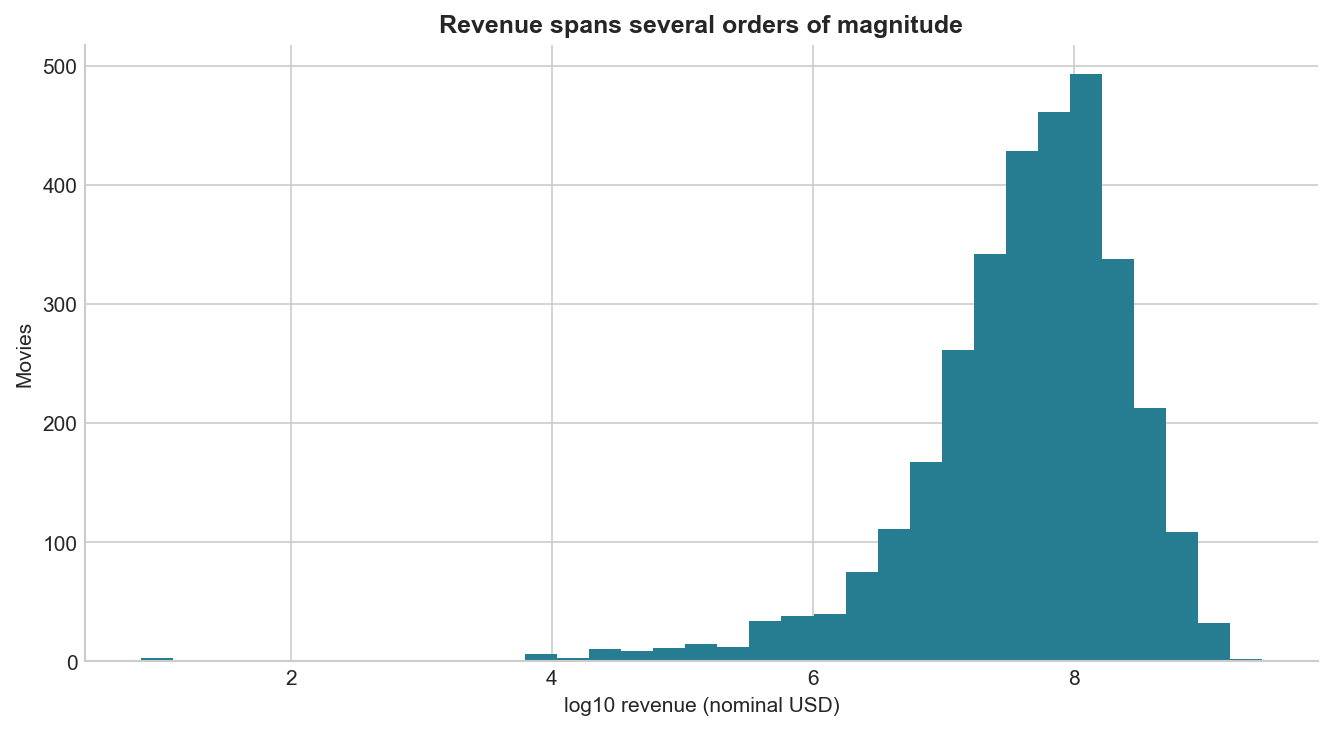

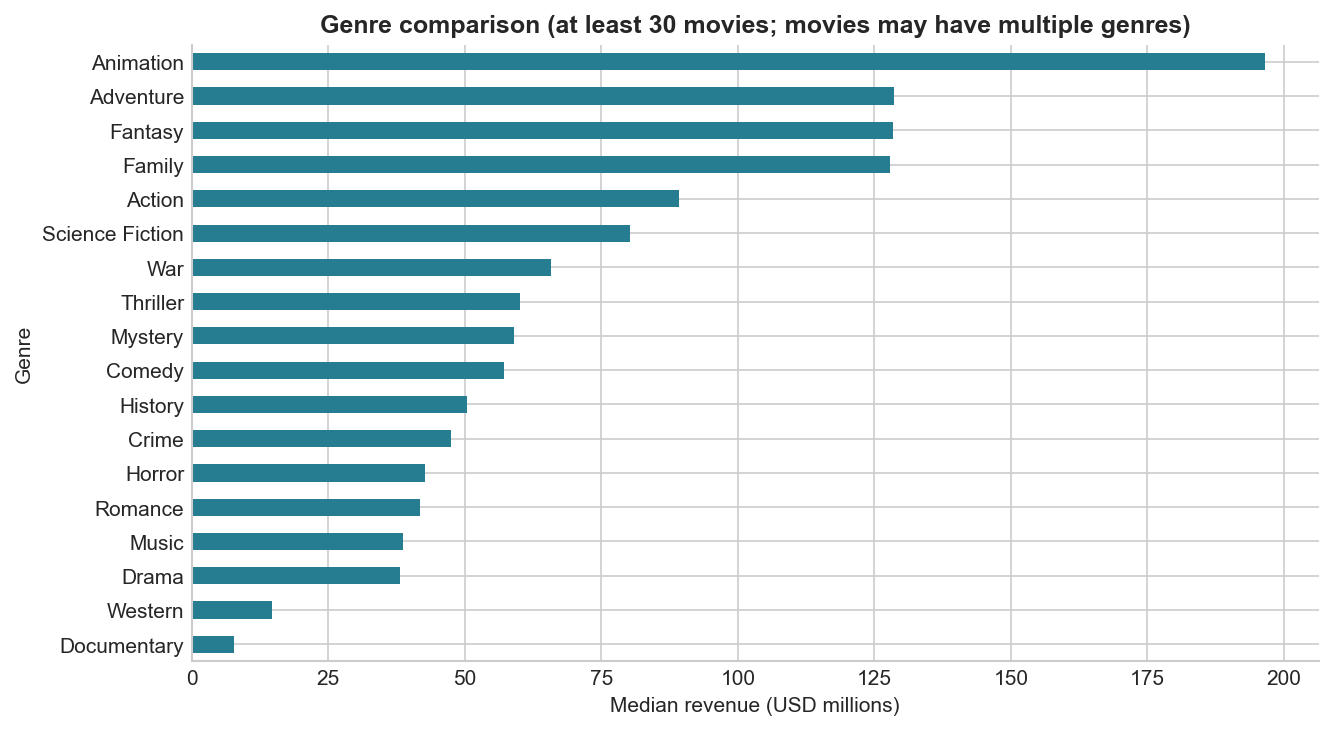

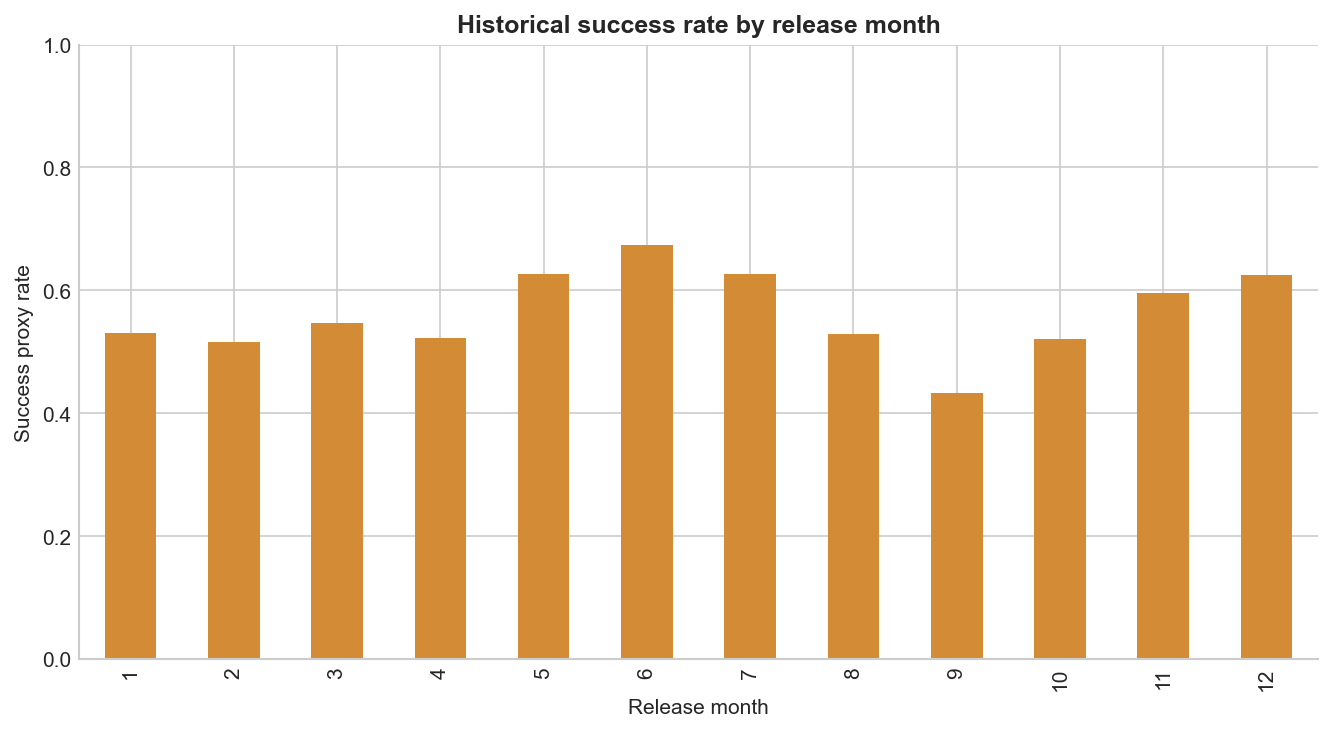

In [3]:
for name in ["budget_revenue", "revenue_distribution", "genre_revenue", "monthly_success"]:
    display(Image(filename=str(ROOT / f"reports/figures/{name}.png"), width=750))

## Training implementation
The following cell exposes the actual candidate definitions and pipeline source. Run `python -m src.train` from the project root to reproduce the experiment. Fixed settings use seed 42; no exhaustive tuning is claimed.

In [4]:
import inspect
import src.train as training
print(inspect.getsource(training.preprocessing))
print(inspect.getsource(training.regression))
print(inspect.getsource(training.main))

def preprocessing():
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), NUMERIC),
        ('category', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=8,
                                  sparse_output=False), CATEGORICAL),
        ('genres', 'passthrough', GENRE_COLS)])

def regression(model, log=True):
    estimator = TransformedTargetRegressor(regressor=model, func=np.log1p,
                    inverse_func=np.expm1) if log else model
    return Pipeline([('prepare', preprocessing()), ('model', estimator)])

def main():
    for folder in [REPORTS, FIGURES, ROOT/'models',ROOT/'data/processed']: folder.mkdir(parents=True, exist_ok=True)
    raw, clean, audit = load_data()
    train, validation, test = split_data(clean)
    parts = {'train':train, 'validation':validation, 'test':test}
    audit['splits'] = {name:{'rows':len(df),'from':str(df.release_dat

## Validation comparisons
Revenue selection minimizes dollar MAE; classification maximizes positive-class F1. Baselines remain eligible.

In [5]:
display(pd.read_csv(ROOT / "reports/regression_validation.csv"))
display(pd.read_csv(ROOT / "reports/classification_validation.csv"))

,Model,MAE,RMSE,R2
0,Random Forest,7.650789e+07,1.455389e+08,0.561697
1,Gradient Boosting,8.244169e+07,1.623779e+08,0.454405
2,Ridge,9.257466e+07,1.839025e+08,0.300171
3,Median baseline,1.256041e+08,2.406744e+08,-0.198606


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
0,Majority baseline,0.591209,0.591209,1.000000,0.743094,0.500000,0.243666
1,Random Forest,0.578022,0.668122,0.568773,0.614458,0.614962,0.240448
2,Logistic Regression,0.507692,0.651007,0.360595,0.464115,0.589599,0.262754


## Final test evaluation
Selected pipelines were refit on train + validation. The 2014–2016 period was reserved for final evaluation.

,selected,baseline
MAE,9.354620e+07,1.555925e+08
RMSE,1.752121e+08,2.866322e+08
R2,5.226517e-01,-2.774894e-01


,selected,baseline
Accuracy,0.621951,0.621951
Precision,0.621951,0.621951
Recall,1.000000,1.000000
F1,0.766917,0.766917
ROC_AUC,0.500000,0.500000
Brier,0.239790,0.239790


Selected models: {'regression': 'Random Forest', 'classification': 'Majority baseline'}


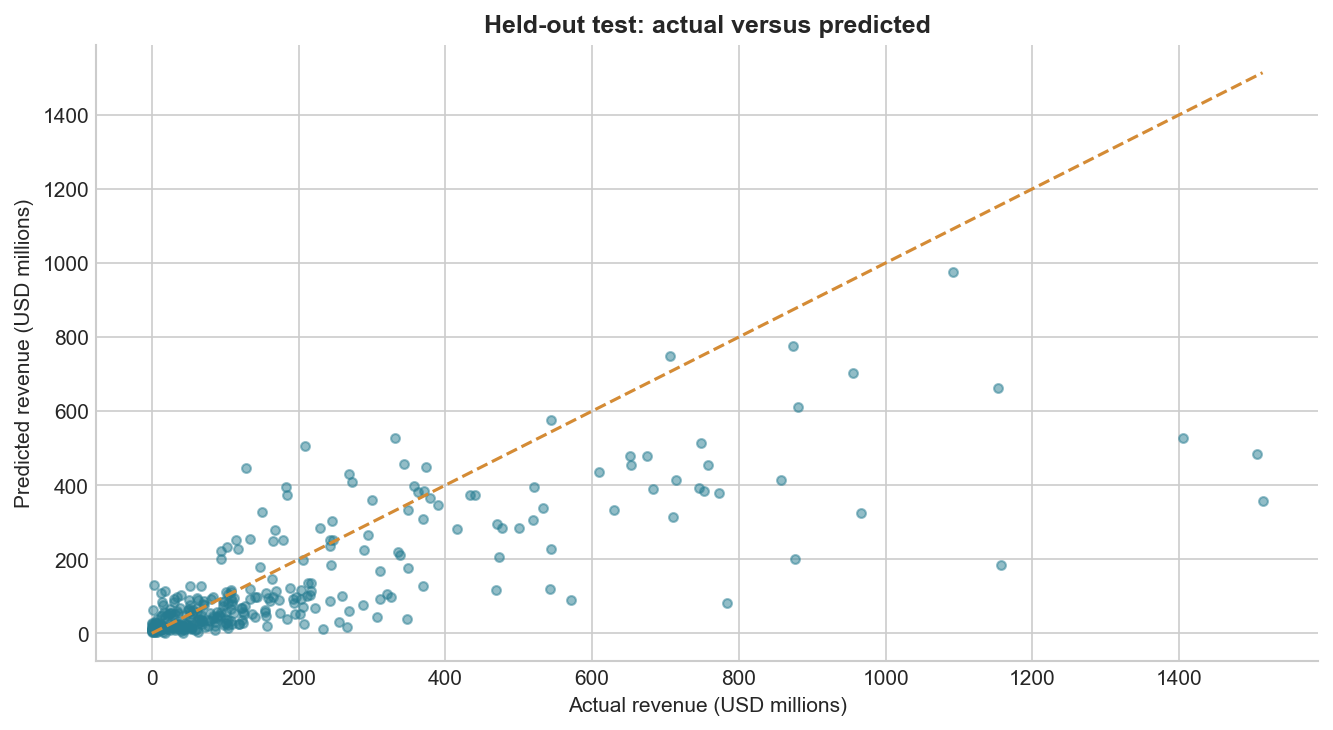

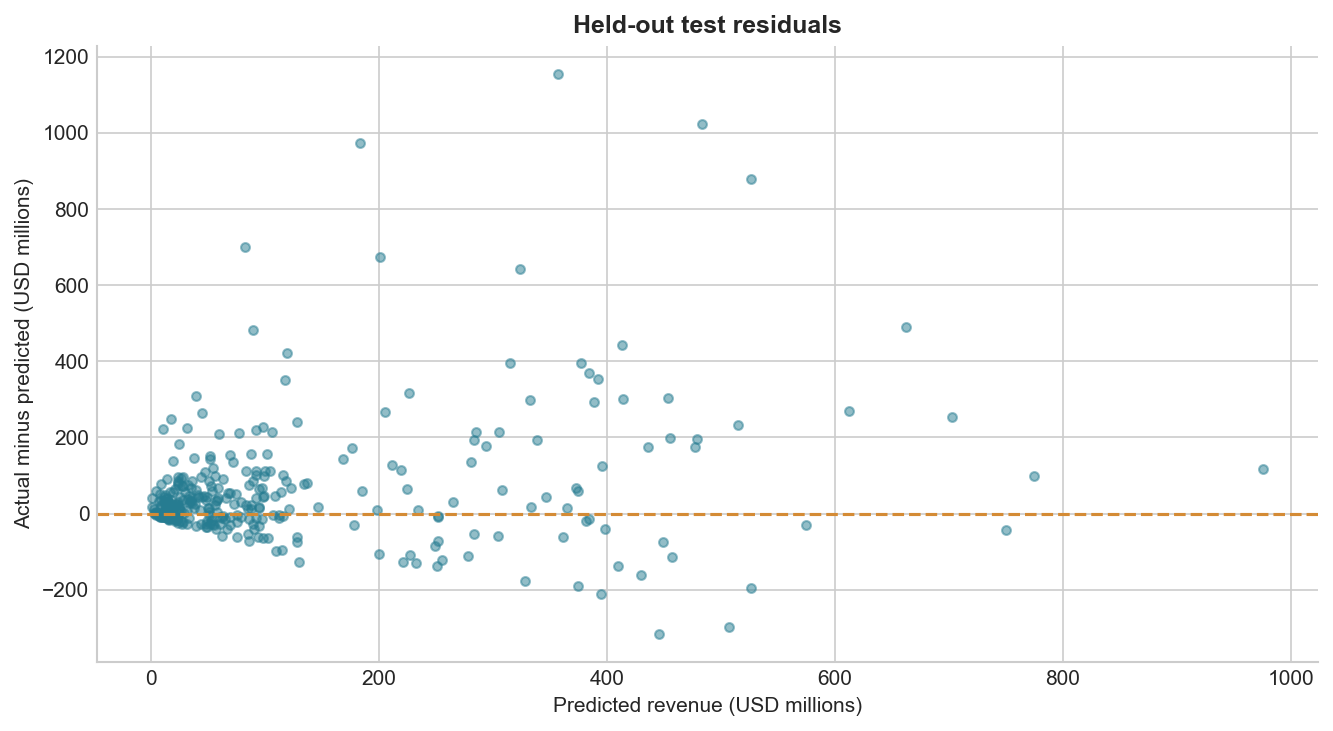

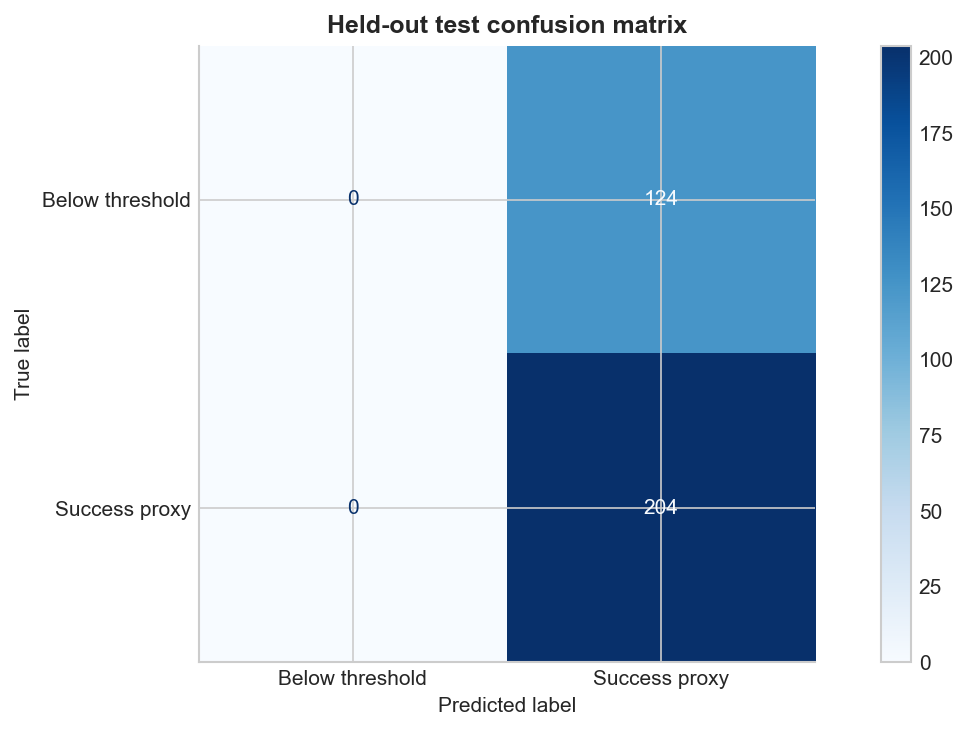

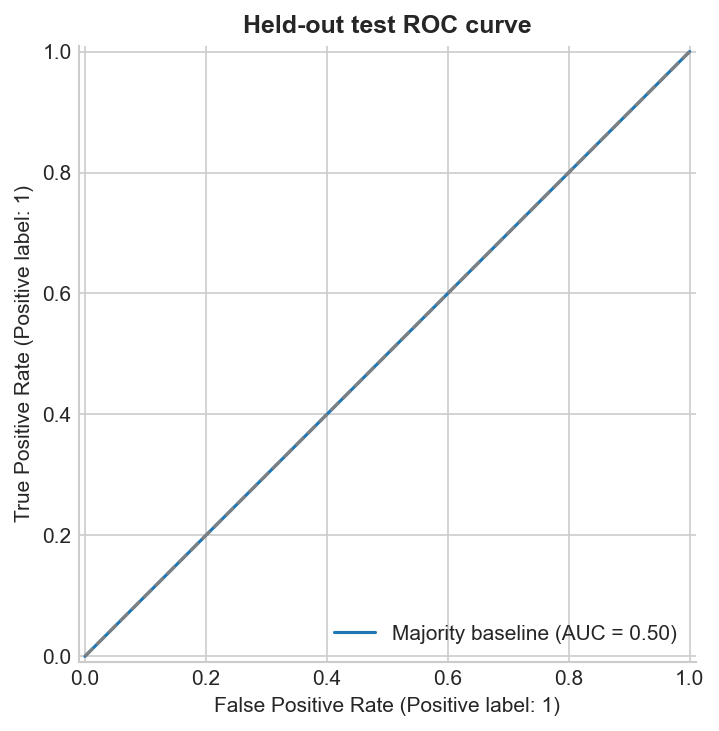

In [6]:
metrics = json.loads((ROOT / "reports/metrics.json").read_text())
display(pd.DataFrame({"selected":metrics["test_regression"],"baseline":metrics["test_regression_baseline"]}))
display(pd.DataFrame({"selected":metrics["test_classification"],"baseline":metrics["test_classification_baseline"]}))
print("Selected models:", metrics["selection"])
for name in ["actual_predicted", "residuals", "confusion_matrix", "roc_curve"]:
    display(Image(filename=str(ROOT / f"reports/figures/{name}.png"), width=750))

## Interpretation and negative results

The majority classifier won validation F1 and has test AUC 0.50. It predicts the same class and
probability for all movies; its high recall/F1 is not evidence of discrimination. Do not present
this as a personalized success predictor. Revenue beats the median baseline but retains large
absolute error. Validation permutation importance describes associations, not causality.

In [7]:
display(pd.read_csv(ROOT / "reports/revenue_importance.csv").head(10))
display(pd.read_csv(ROOT / "reports/largest_errors.csv").head(10))

,Feature,Importance,Std
0,log_budget,7.017130e+07,1.838277e+06
1,runtime,3.812112e+06,6.686827e+05
2,genre_Adventure,9.207689e+05,7.881583e+04
3,genre_Drama,7.263750e+05,3.792927e+05
4,genre_Comedy,4.989096e+05,9.508666e+04
5,genre_Animation,4.463621e+05,2.445372e+05
6,primary_company,3.788415e+05,8.616250e+04
7,month_cos,2.943953e+05,2.358901e+05
8,month_sin,2.303911e+05,4.180211e+05
9,original_language,2.120358e+05,1.242902e+05


,id,title,release_date,budget,revenue,success,predicted_revenue,absolute_error,success_probability,predicted_success
0,135397,Jurassic World,2015-06-09,150000000,1513528810,1,3.574845e+08,1.156044e+09,0.55367,1
1,168259,Furious 7,2015-04-01,190000000,1506249360,1,4.837004e+08,1.022549e+09,0.55367,1
2,211672,Minions,2015-06-17,74000000,1156730962,1,1.834690e+08,9.732620e+08,0.55367,1
3,99861,Avengers: Age of Ultron,2015-04-22,280000000,1405403694,1,5.267896e+08,8.786141e+08,0.55367,1
4,293660,Deadpool,2016-02-09,58000000,783112979,1,8.269242e+07,7.004206e+08,0.55367,1
5,328111,The Secret Life of Pets,2016-06-18,75000000,875958308,1,2.012755e+08,6.746828e+08,0.55367,1
6,278927,The Jungle Book,2016-04-07,175000000,966550600,1,3.240090e+08,6.425416e+08,0.55367,1
7,271110,Captain America: Civil War,2016-04-27,250000000,1153304495,1,6.624445e+08,4.908600e+08,0.55367,1
8,216015,Fifty Shades of Grey,2015-02-11,40000000,571006128,1,8.922694e+07,4.817792e+08,0.55367,1
9,150540,Inside Out,2015-06-09,175000000,857611174,1,4.135537e+08,4.440575e+08,0.55367,1


## Saved-pipeline inference
Use precisely the same feature construction for training and new inputs.

In [8]:
import joblib
reg = joblib.load(ROOT / "models/revenue_pipeline.joblib")
clf = joblib.load(ROOT / "models/success_pipeline.joblib")
scenario = pd.DataFrame([{"budget":30000000,"runtime":110,"release_year":2015,
    "release_month":6,"original_language":"en","primary_company":"Unknown",
    "director":"Unknown","genres_list":["Drama"]}])
features=make_features(scenario)
print(f"Estimated revenue: ${max(0,reg.predict(features)[0]):,.0f}")
print(f"Success baseline probability (not individualized): {clf.predict_proba(features)[0,1]:.1%}")

Estimated revenue: $70,257,773
Success baseline probability (not individualized): 55.4%


## Limitations and next research

Historical selected sample, uncertain financial reporting, nominal currency without inflation
adjustment, incomplete 2016 coverage, unverified historical metadata availability, and no marketing
or distribution features limit reliability. Predefine a balanced classification objective, obtain
better predictors, and evaluate future revisions on a fresh untouched test period.

Source: https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata